In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts run parameter N_SHOTS and frontier columns: epsilon, p_star.

    Returns:
        epsilon  : np.ndarray
        p_star   : np.ndarray
        n_shots  : int
    """
    epsilons = []
    p_stars  = []
    n_shots  = None

    with open(filepath, "r") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        # ── Extract N_SHOTS from [RUN PARAMETERS] ─────────────────────────────
        if line.startswith("N_SHOTS"):
            n_shots = int(line.split(":")[1].strip())
            continue

        # ── Detect start of data section ──────────────────────────────────────
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue  # skip the header row

        # ── Skip separator line ───────────────────────────────────────────────
        if in_data_section and set(line) <= set("-"):
            continue

        # ── Parse data rows ───────────────────────────────────────────────────
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        n_shots,
    )


# ── Usage ─────────────────────────────────────────────────────────────────────
ALPHA = 0.05
epsilon, p_star, n_shots = parse_iqae_ceiling_file("data100.txt")

print(f"N_SHOTS: {n_shots}")  # N_SHOTS: 100

N_SHOTS: 100


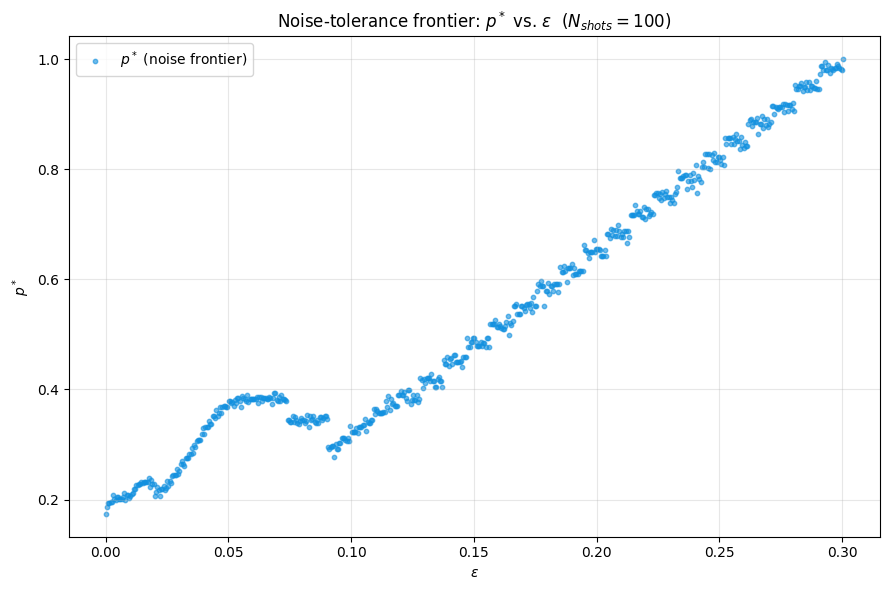

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(epsilon, p_star, color="#1190df", s=10, alpha=0.6,
           label=r"$p^*$ (noise frontier)")

ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$p^*$")
ax.set_title(rf"Noise-tolerance frontier: $p^*$ vs. $\varepsilon$  $(N_{{shots}} = {n_shots})$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES — imports, problem definition, noise model, N_max
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

from qiskit.circuit import QuantumCircuit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

# ── Fixed experiment parameters ────────────────────────────────────────────────
p_true = 0.2
ALPHA  = 0.05
N_JOBS = 18


# ── Bernoulli amplitude estimation problem ─────────────────────────────────────
class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k


problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")


# ── Noise model builder ────────────────────────────────────────────────────────
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error: λ ∈ [0, 1] is the
# physically meaningful range (λ=1 is full depolarization).
MAX_PHYSICAL_DEPOL = 1.0

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        p_1q = min(p_depol, MAX_PHYSICAL_DEPOL)
        error_1q = depolarizing_error(p_1q, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler


# ── Ceiling shot budget N_max(eps, alpha) ─────────────────────────────────────
def N_max(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

print("Prerequisites loaded ✅")

All imports OK ✅
Problem defined ✅
Prerequisites loaded ✅


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL A 
# ══════════════════════════════════════════════════════════════════════════════
def _safe_float(x):
    return float(x) if x is not None else None

def _safe_list(x):
    return list(x) if x is not None else None

def _safe_list_of_lists(x):
    return [list(item) for item in x] if x is not None else None


def single_diag_run_full(eps, p_noise, n_shots):
    """
    One IQAE run at (eps, p_noise) with shot budget n_shots.
    Captures the full IterativeAmplitudeEstimationResult, excluding
    circuit_results (raw statevector/counts — not needed here).
    Each field is converted defensively so a single None/missing field
    doesn't discard the whole run.
    """
    try:
        sampler = build_noisy_sampler(p_noise, n_shots)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
        )
        result = iae.estimate(problem)

        powers   = list(result.powers) if result.powers is not None else []
        K_values = [2 * k + 1 for k in powers]

        estimate = _safe_float(result.estimation_processed)
        success  = int(estimate is not None and abs(estimate - p_true) <= eps)

        return {
            "success"                      : success,
            "powers"                       : powers,
            "K_values"                     : K_values,
            "T_eps"                        : len(powers),
            "max_K"                        : max(K_values) if K_values else None,
            "sum_K"                        : sum(K_values) if K_values else None,

            # amplitude-domain results
            "estimation"                   : estimate,
            "signed_error"                 : (estimate - p_true) if estimate is not None else None,
            "confidence_interval"          : _safe_list(result.confidence_interval),
            "confidence_interval_processed": _safe_list(result.confidence_interval_processed),
            "estimate_intervals"           : _safe_list_of_lists(result.estimate_intervals),

            # angle-domain results
            "theta_intervals"              : _safe_list_of_lists(result.theta_intervals),

            # schedule / information mechanics
            "ratios"                       : _safe_list(result.ratios),
            "num_oracle_queries"           : int(result.num_oracle_queries) if result.num_oracle_queries is not None else None,

            # precision bookkeeping
            "epsilon_target"               : _safe_float(result.epsilon_target),
            "epsilon_estimated"            : _safe_float(result.epsilon_estimated),
            "epsilon_estimated_processed"  : _safe_float(result.epsilon_estimated_processed),
            "alpha_echo"                   : _safe_float(result.alpha),

            # sampling bookkeeping
            "shots"                        : result.shots,
            "n_shots_requested"            : n_shots,

            "error_message"                : None,
        }

    except Exception as e:
        err_str = f"{type(e).__name__}: {e}"
        print(f"[WARN] single_diag_run_full failed: {err_str}")
        return {
            "success": 0, "powers": [], "K_values": [], "T_eps": 0,
            "max_K": None, "sum_K": None,
            "estimation": None, "signed_error": None,
            "confidence_interval": None, "confidence_interval_processed": None,
            "estimate_intervals": None, "theta_intervals": None,
            "ratios": None, "num_oracle_queries": None,
            "epsilon_target": eps, "epsilon_estimated": None,
            "epsilon_estimated_processed": None, "alpha_echo": ALPHA,
            "shots": None, "n_shots_requested": n_shots,
            "error_message": err_str,
        }

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL B
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from joblib import Parallel, delayed
import numpy as np

N_DIAG = 200   # runs per point

diag_results = []

for eps, p_star_val in zip(epsilon, p_star):
    n_shots_diag = n_shots

    print(f"\n{'─'*60}")
    print(f"ε={eps:.6f} | p*={p_star_val:.6f} | N_shots={n_shots_diag} "
          f"| running {N_DIAG} runs ...")

    runs = Parallel(n_jobs=N_JOBS)(
        delayed(single_diag_run_full)(eps, p_star_val, n_shots_diag)
        for _ in range(N_DIAG)
    )

    # ── Live per-run schedule output ─────────────────────────────────────────
    for i, run in enumerate(runs):
        if run["error_message"] is not None:
            print(f"  run {i+1:>3} | ERROR: {run['error_message']}")
            continue

        status  = "✅" if run["success"] else "❌"
        err_str = f"{run['signed_error']:.6f}" if run["signed_error"] is not None else "N/A"
        print(f"  run {i+1:>3} | {status} | T={run['T_eps']:>2} | "
              f"K_values={run['K_values']} | signed_error={err_str}")

    # ── Aggregate ──────────────────────────────────────────────────────────
    valid_runs   = [r for r in runs if r["T_eps"] > 0]
    success_rate = np.mean([r["success"] for r in runs])

    T_values    = [r["T_eps"]  for r in valid_runs]
    maxK_values = [r["max_K"]  for r in valid_runs]
    sumK_values = [r["sum_K"]  for r in valid_runs]
    err_values  = [r["signed_error"] for r in valid_runs if r["signed_error"] is not None]

    schedule_counts = Counter(tuple(r["K_values"]) for r in valid_runs)
    most_common_schedule, most_common_count = (
        schedule_counts.most_common(1)[0] if schedule_counts else ((), 0)
    )

    diag_results.append({
        "epsilon"              : eps,
        "p_star"               : p_star_val,
        "n_shots"              : n_shots_diag,
        "success_rate"         : success_rate,
        "T_mean"               : float(np.mean(T_values)) if T_values else None,
        "T_std"                : float(np.std(T_values))  if T_values else None,
        "max_K_mean"           : float(np.mean(maxK_values)) if maxK_values else None,
        "sum_K_mean"           : float(np.mean(sumK_values)) if sumK_values else None,
        "mean_signed_error"    : float(np.mean(err_values)) if err_values else None,
        "most_common_schedule" : list(most_common_schedule),
        "most_common_count"    : most_common_count,
        "n_valid_runs"         : len(valid_runs),
        "raw_runs"             : runs,
    })

    print(f"  → success_rate={success_rate:.3f} | "
          f"most_common_schedule={list(most_common_schedule)} "
          f"({most_common_count}/{len(valid_runs)})")

print("\n✅ Full diagnostic sweep complete.")


────────────────────────────────────────────────────────────
ε=0.000100 | p*=0.173828 | N_shots=100 | running 200 runs ...
  run   1 | ❌ | T= 9 | K_values=[1, 1, 1, 1, 7, 23, 103, 513, 2653] | signed_error=0.025040
  run   2 | ✅ | T= 9 | K_values=[1, 1, 1, 1, 5, 19, 83, 435, 2271] | signed_error=0.000006
  run   3 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 15, 69, 347, 1749] | signed_error=0.000059
  run   4 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 19, 87, 425, 2169] | signed_error=0.000043
  run   5 | ✅ | T= 9 | K_values=[1, 1, 1, 1, 5, 19, 87, 429, 2167] | signed_error=-0.000011
  run   6 | ❌ | T= 9 | K_values=[1, 1, 1, 1, 7, 27, 111, 529, 2673] | signed_error=0.004821
  run   7 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 15, 63, 297, 1531] | signed_error=-0.000076
  run   8 | ✅ | T= 9 | K_values=[1, 1, 1, 1, 5, 23, 111, 531, 2771] | signed_error=-0.000023
  run   9 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 15, 73, 375, 1933] | signed_error=-0.000009
  run  10 | ✅ | T= 8 | K_values=[1, 1, 1, 5, 19, 87, 425, 2163

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL C
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pickle

eps_out      = []
p_star_out   = []
T_out        = []
K_values_out = []
ratios_out   = []
success_out  = []   # NEW: needed to filter T by success in Cell D

for point in diag_results:
    eps_val    = point["epsilon"]
    p_star_val = point["p_star"]

    for run in point["raw_runs"]:
        eps_out.append(eps_val)
        p_star_out.append(p_star_val)
        T_out.append(run["T_eps"])
        K_values_out.append(run["K_values"])   # variable-length list, kept as-is
        ratios_out.append(run["ratios"])       # variable-length list, kept as-is
        success_out.append(bool(run["success"]))

eps_arr      = np.array(eps_out)
p_star_arr   = np.array(p_star_out)
T_arr        = np.array(T_out)
K_values_arr = np.array(K_values_out, dtype=object)   # ragged array of lists
ratios_arr   = np.array(ratios_out, dtype=object)     # ragged array of lists
success_arr  = np.array(success_out, dtype=bool)

print(f"Exported {len(eps_arr)} run records "
      f"across {len(diag_results)} epsilon points.")

# ── Save to disk ────────────────────────────────────────────────────────────
np.savez(
    "iqae_shots100.npz",
    epsilon=eps_arr,
    p_star=p_star_arr,
    T=T_arr,
    K_values=K_values_arr,
    ratios=ratios_arr,
    success=success_arr,
    allow_pickle=True,
)

print("✅ Saved to iqae_shots100.npz")

Exported 120200 run records across 601 epsilon points.
✅ Saved to iqae_shots100.npz


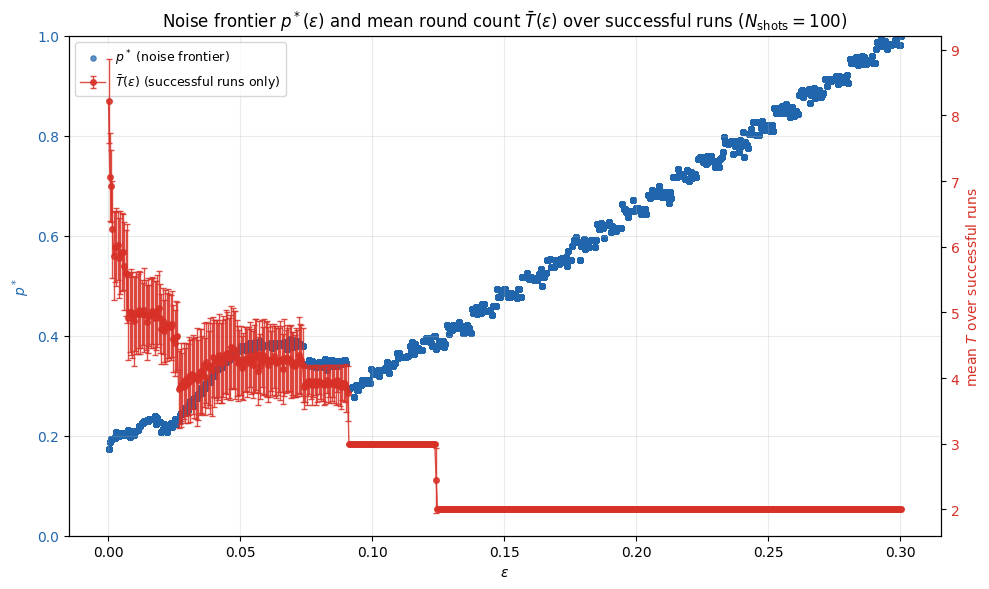

In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL D — Plot: epsilon vs p_star, and mean T over SUCCESSFUL runs (dual y-axis)
# ══════════════════════════════════════════════════════════════════════════════


import matplotlib.pyplot as plt
import numpy as np


data = np.load("iqae_shots100.npz", allow_pickle=True)
eps_arr      = data["epsilon"]
p_star_arr   = data["p_star"]
T_arr        = data["T"]
K_values_arr = data["K_values"]
ratios_arr   = data["ratios"]
success_arr  = data["success"]   # NEW


# ── Per-point values (one per epsilon, from diag_results) ────────────────────
eps_points = eps_arr
p_star_pts = p_star_arr

# ── Aggregate T over successful runs only, per unique epsilon ───────────────
unique_eps = np.unique(eps_arr)
eps_agg        = []
T_succ_mean    = []
T_succ_std     = []
n_succ_arr     = []

for eps_val in unique_eps:
    mask = (eps_arr == eps_val) & success_arr
    if np.any(mask):
        eps_agg.append(eps_val)
        T_succ_mean.append(T_arr[mask].mean())
        T_succ_std.append(T_arr[mask].std())
        n_succ_arr.append(mask.sum())
    else:
        # no successful runs at this epsilon — skip rather than plot a
        # meaningless average, but flag it
        print(f"⚠ no successful runs at ε={eps_val:.6f}, omitted from T plot")

eps_agg     = np.array(eps_agg)
T_succ_mean = np.array(T_succ_mean)
T_succ_std  = np.array(T_succ_std)

fig, ax1 = plt.subplots(figsize=(10, 6))

# ── Left axis: p_star ─────────────────────────────────────────────────────────
color_p = "#2166ac"
ax1.scatter(eps_points, p_star_pts, color=color_p, s=14, alpha=0.7,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)

# ── Right axis: mean T over successful runs, per epsilon ────────────────────
ax2 = ax1.twinx()
color_T = "#d73027"
ax2.errorbar(eps_agg, T_succ_mean, yerr=T_succ_std, fmt="o-",
             color=color_T, markersize=4, linewidth=1, capsize=2, alpha=0.85,
             label=r"$\bar{T}(\varepsilon)$ (successful runs only)")
ax2.set_ylabel(r"mean $T$ over successful runs", color=color_T)
ax2.tick_params(axis="y", labelcolor=color_T)

ax1.set_title(
    rf"Noise frontier $p^*(\varepsilon)$ and mean round count "
    rf"$\bar{{T}}(\varepsilon)$ over successful runs $(N_{{\mathrm{{shots}}}} = {n_shots})$"
)
ax1.grid(True, alpha=0.25)

# ── Combined legend ───────────────────────────────────────────────────────────
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()